In [329]:
pip install pandas pingouin scikit-posthocs

In [330]:
import pandas as pd
import pingouin as pg
import scikit_posthocs as sp
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

#Calculation of the IC50

##3,4-DIA with MDA-MB-231

In [331]:
data_34_dia_mda = pd.DataFrame({
    'Viability': [99.15254237,	100,	98.30508475,	96.61016949,	100,	98.30508475,	97.45762712,	99.15254237,	99.15254237,
                   95.17045455,96.02272727,96.30681818,94.03409091,98.01136364,96.875,98.86363636,96.30681818,98.01136364,
                   89.48863636,91.19318182,90.625,90.34090909,92.04545455,92.61363636,90.34090909,92.61363636,93.75,
                   75.28409091,76.13636364,76.98863636,75,74.71590909,73.57954545,77.27272727,78.40909091,76.42045455,
                   64.48863636,62.78409091,61.64772727,63.06818182,63.63636364,65.90909091,63.63636364,65.05681818,59.94318182,
                   34.94318182,34.65909091,34.94318182,36.64772727,36.07954545,35.79545455,34.94318182,35.51136364,36.64772727
],
    'Group': ['0']*9 + ['10']*9 + ['25']*9 + ['50']*9 + ['75']*9 + ['100']*9
})

In [332]:
data_34_dia_mda['Concentration'] = data_34_dia_mda['Group'].astype(float)

In [333]:
group = data_34_dia_mda.groupby('Concentration')['Viability']
mean_viability = group.mean()
sem_viability  = group.sem()

In [334]:
# Hill Equation
def hill_equation(x, bottom, top, ic50, hill_slope):
    return bottom + (top - bottom) / (1 + (x / ic50)**hill_slope)

# Prepare data for fitting
xdata = mean_viability.index.values
ydata = mean_viability.values
p0 = [ydata.min(), ydata.max(), np.median(xdata), 1.0]

In [335]:
# Non-linear fitting
popt, pcov = curve_fit(hill_equation, xdata, ydata, p0=p0,
                       bounds=([0, 0, 0, 0], [100, 100, np.inf, np.inf]))
bottom, top, ic50, hill_slope = popt

In [336]:
print(f"Fitted parameters:")
print(f"  Bottom      = {bottom:.2f} %")
print(f"  Top         = {top:.2f} %")
print(f"  IC₅₀        = {ic50:.2f} µM")
print(f"  Hill slope  = {hill_slope:.2f}")

Fitted parameters:
  Bottom      = 0.00 %
  Top         = 96.61 %
  IC₅₀        = 86.76 µM
  Hill slope  = 2.71


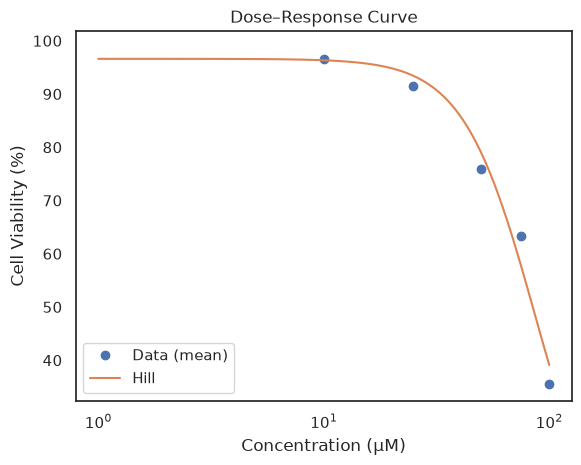

In [337]:
x_fit = np.logspace(np.log10(xdata.min()+1), np.log10(xdata.max()), 100)
y_fit = hill_equation(x_fit, *popt)

fig, ax = plt.subplots()
ax.plot(xdata, ydata, 'o', label='Data (mean)')
ax.plot(x_fit, y_fit, '-', label='Hill')
ax.set_xscale('log')
ax.set_xlabel('Concentration (µM)')
ax.set_ylabel('Cell Viability (%)')
ax.set_title('Dose–Response Curve')
ax.legend()
plt.show()

##3,4-DIA with MCF7

In [338]:
data_34_dia_mc = pd.DataFrame({
    'Viability': [99.15254237,	100,	98.30508475,	96.61016949,	100,	98.30508475,	97.45762712,	99.15254237,	99.15254237,
                   84.14872798,87.47553816,85.32289628,84.73581213,84.3444227,83.95303327,87.86692759,88.45401174,86.49706458,
                   67.12328767,66.53620352,71.23287671,70.25440313,68.6888454,68.29745597,72.01565558,70.64579256,72.01565558,
                   59.88258317,60.86105675,61.64383562,58.51272016,58.90410959,60.2739726,61.83953033,61.83953033,62.42661448,
                   42.27005871,42.46575342,43.24853229,42.46575342,41.68297456,39.33463796,39.92172211,40.31311155,40.50880626,
                   39.53033268,40.31311155,40.50880626,36.2035225,36.98630137,35.42074364,36.39921722,36.39921722,35.61643836
],
    'Group': ['0']*9 + ['10']*9 + ['25']*9 + ['50']*9 + ['75']*9 + ['100']*9
})

In [339]:
data_34_dia_mc['Concentration'] = data_34_dia_mda['Group'].astype(float)

In [340]:
group = data_34_dia_mc.groupby('Concentration')['Viability']
mean_viability = group.mean()
sem_viability  = group.sem()

In [341]:
# Hill Equation
def hill_equation(x, bottom, top, ic50, hill_slope):
    return bottom + (top - bottom) / (1 + (x / ic50)**hill_slope)

# Prepare data for fitting
xdata = mean_viability.index.values
ydata = mean_viability.values
p0 = [ydata.min(), ydata.max(), np.median(xdata), 1.0]

In [342]:
# Non-linear fitting
popt, pcov = curve_fit(hill_equation, xdata, ydata, p0=p0,
                       bounds=([0, 0, 0, 0], [100, 100, np.inf, np.inf]))
bottom, top, ic50, hill_slope = popt

In [343]:
print(f"Fitted parameters:")
print(f"  Bottom      = {bottom:.2f} %")
print(f"  Top         = {top:.2f} %")
print(f"  IC₅₀        = {ic50:.2f} µM")
print(f"  Hill slope  = {hill_slope:.2f}")

Fitted parameters:
  Bottom      = 0.00 %
  Top         = 98.26 %
  IC₅₀        = 63.56 µM
  Hill slope  = 1.07


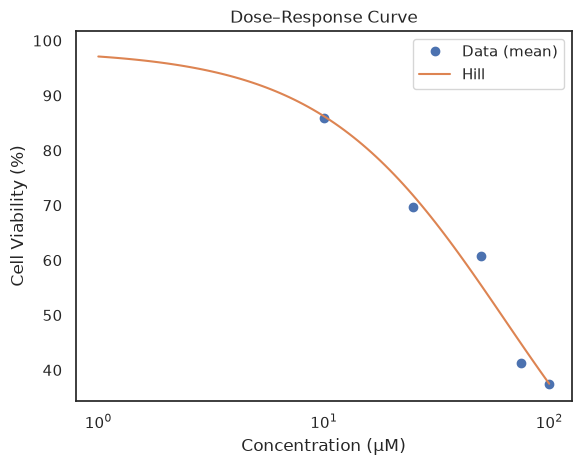

In [344]:
x_fit = np.logspace(np.log10(xdata.min()+1), np.log10(xdata.max()), 100)
y_fit = hill_equation(x_fit, *popt)

fig, ax = plt.subplots()
ax.plot(xdata, ydata, 'o', label='Data (mean)')
ax.plot(x_fit, y_fit, '-', label='Hill')
ax.set_xscale('log')
ax.set_xlabel('Concentration (µM)')
ax.set_ylabel('Cell Viability (%)')
ax.set_title('Dose–Response Curve')
ax.legend()
plt.show()

##3,5-DIA with MDA-MB-231

In [345]:
data_35_dia_mda = pd.DataFrame({
    'Viability': [99.15254237,	100,	98.30508475,	96.61016949,	100,	98.30508475,	97.45762712,	99.15254237,	99.15254237,
                   98.29545455,99.14772727,99.431818,97.15909091,99.71590909,98.86363636,98.57954545,99.43181818,96.875,
                   94.03409091,95.17045455,94.60227273,94.31818182,96.02272727,97.15909091,94.31818182,97.44318182,97.72727273,
                   78.97727273,79.82954545,80.68181818,79.54545455,80.39772727,77.27272727,80.96590909,82.10227273,80.11363636,
                   64.48863636,62.78409091,64.48863636,63.35227273,63.63636364,65.05681818,64.77272727,62.78409091,63.06818182,
                   38.06818182,37.78409091,38.06818182,36.07954545,36.36363636,36.07954545,35.22727273,38.63636364,34.375
],
    'Group': ['0']*9 + ['10']*9 + ['25']*9 + ['50']*9 + ['75']*9 + ['100']*9
})

In [346]:
data_35_dia_mda['Concentration'] = data_34_dia_mda['Group'].astype(float)

In [347]:
group = data_35_dia_mda.groupby('Concentration')['Viability']
mean_viability = group.mean()
sem_viability  = group.sem()

In [348]:
# Hill Equation
def hill_equation(x, bottom, top, ic50, hill_slope):
    return bottom + (top - bottom) / (1 + (x / ic50)**hill_slope)

# Prepare data for fitting
xdata = mean_viability.index.values
ydata = mean_viability.values
p0 = [ydata.min(), ydata.max(), np.median(xdata), 1.0]

In [349]:
# Non-linear fitting
popt, pcov = curve_fit(hill_equation, xdata, ydata, p0=p0,
                       bounds=([0, 0, 0, 0], [100, 100, np.inf, np.inf]))
bottom, top, ic50, hill_slope = popt

In [350]:
print(f"Fitted parameters:")
print(f"  Bottom      = {bottom:.2f} %")
print(f"  Top         = {top:.2f} %")
print(f"  IC―₀        = {ic50:.2f} µM")
print(f"  Hill slope  = {hill_slope:.2f}")

Fitted parameters:
  Bottom      = 0.00 %
  Top         = 98.13 %
  IC―₀        = 87.13 µM
  Hill slope  = 3.03


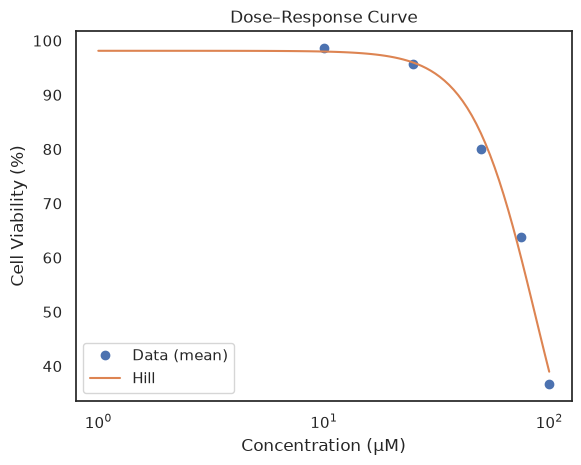

In [351]:
x_fit = np.logspace(np.log10(xdata.min()+1), np.log10(xdata.max()), 100)
y_fit = hill_equation(x_fit, *popt)

fig, ax = plt.subplots()
ax.plot(xdata, ydata, 'o', label='Data (mean)')
ax.plot(x_fit, y_fit, '-', label='Hill')
ax.set_xscale('log')
ax.set_xlabel('Concentration (µM)')
ax.set_ylabel('Cell Viability (%)')
ax.set_title('Dose–Response Curve')
ax.legend()
plt.show()

##3,5-DIA with MCF7

In [352]:
data_35_dia_mc = pd.DataFrame({
    'Viability': [99.15254237,	100,	98.30508475,	96.61016949,	100,	98.30508475,	97.45762712,	99.15254237,	99.15254237,
                   90.60665362,92.17221135,91.38943249,90.4109589,90.60665362,92.95499022,91.5851272,90.60665362,90.60665362,
                   72.01565558,72.79843444,72.21135029,73.97260274,73.77690802,72.60273973,71.62426614,71.23287671,71.23287671,
                   62.6223092,63.20939335,63.60078278,64.77495108,65.36203523,65.75342466,64.77495108,66.34050881,66.34050881,
                   41.29158513,42.66144814,41.87866928,40.31311155,41.29158513,40.90019569,43.05283757,42.85714286,43.83561644,
                   38.35616438,35.42074364,35.8121331,38.5518591,35.22504892,37.57338552,36.39921722,34.83365949,36.2035225
],
    'Group': ['0']*9 + ['10']*9 + ['25']*9 + ['50']*9 + ['75']*9 + ['100']*9
})

In [353]:
#data_35_dia_mc['Concentration'] = data_34_dia_mda['Group'].astype(float)

In [354]:
data_35_dia_mc['Concentration'] = data_35_dia_mc['Group'].astype(float)

In [355]:
group = data_35_dia_mc.groupby('Concentration')['Viability']
mean_viability = group.mean()
sem_viability  = group.sem()

In [356]:
# Hill Equation
def hill_equation(x, bottom, top, ic50, hill_slope):
    return bottom + (top - bottom) / (1 + (x / ic50)**hill_slope)

# Prepare data for fitting
xdata = mean_viability.index.values
ydata = mean_viability.values
p0 = [ydata.min(), ydata.max(), np.median(xdata), 1.0]

In [357]:
# Non-linear fitting
popt, pcov = curve_fit(hill_equation, xdata, ydata, p0=p0,
                       bounds=([0, 0, 0, 0], [100, 100, np.inf, np.inf]))
bottom, top, ic50, hill_slope = popt

In [358]:
print(f"Fitted parameters:")
print(f"  Bottom      = {bottom:.2f} %")
print(f"  Top         = {top:.2f} %")
print(f"  IC₅₀        = {ic50:.2f} µM")
print(f"  Hill slope  = {hill_slope:.2f}")

Fitted parameters:
  Bottom      = 0.00 %
  Top         = 98.38 %
  IC₅₀        = 66.73 µM
  Hill slope  = 1.28


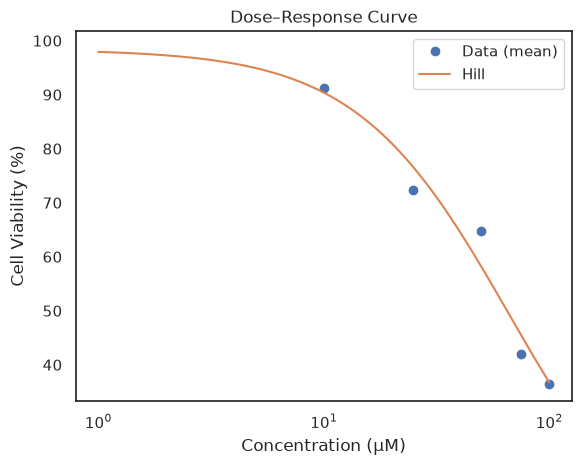

In [359]:
x_fit = np.logspace(np.log10(xdata.min()+1), np.log10(xdata.max()), 100)
y_fit = hill_equation(x_fit, *popt)

fig, ax = plt.subplots()
ax.plot(xdata, ydata, 'o', label='Data (mean)')
ax.plot(x_fit, y_fit, '-', label='Hill')
ax.set_xscale('log')
ax.set_xlabel('Concentration (µM)')
ax.set_ylabel('Cell Viability (%)')
ax.set_title('Dose–Response Curve')
ax.legend()
plt.show()

##Concentration-dependent effect

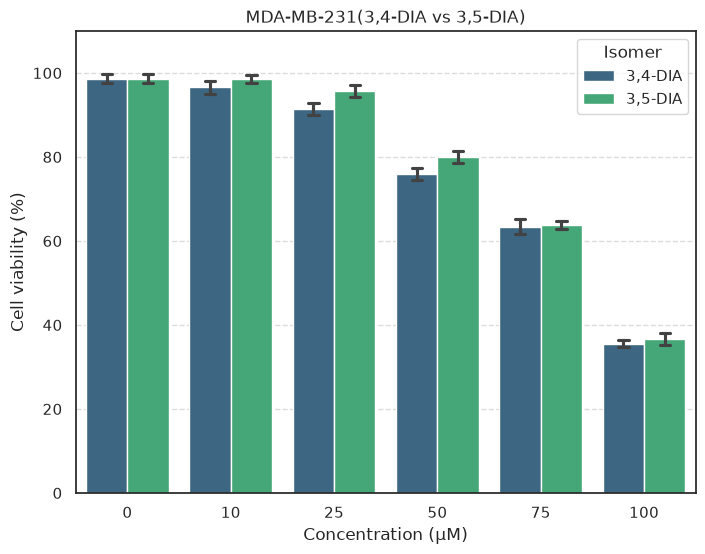

In [360]:
data_34_dia_mda['Dataset'] = '3,4-DIA'
data_35_dia_mda['Dataset'] = '3,5-DIA'

combined_data = pd.concat([data_34_dia_mda, data_35_dia_mda])

plt.figure(figsize=(8, 6))
sns.barplot(data=combined_data, x='Group', y='Viability', hue='Dataset', errorbar='sd', capsize=0.2, palette='viridis')

plt.title('MDA-MB-231(3,4-DIA vs 3,5-DIA)')
plt.xlabel('Concentration (\u03bcM)')
plt.ylabel('Cell viability (%)')
plt.ylim(0, 110) # Set y-axis limit for better visualization
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Isomer')
plt.show()

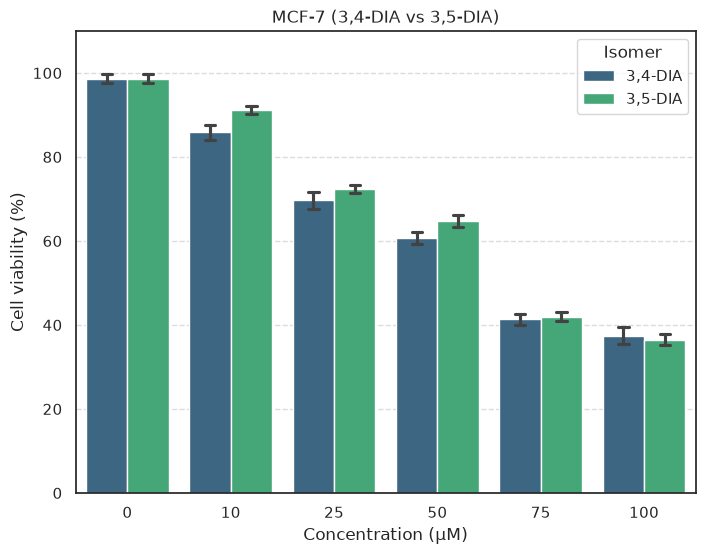

In [361]:
data_34_dia_mc['Dataset'] = '3,4-DIA'
data_35_dia_mc['Dataset'] = '3,5-DIA'

combined_data = pd.concat([data_34_dia_mc, data_35_dia_mc])

plt.figure(figsize=(8, 6))
sns.barplot(data=combined_data, x='Group', y='Viability', hue='Dataset', errorbar='sd', capsize=0.2, palette='viridis')

plt.title('MCF-7 (3,4-DIA vs 3,5-DIA)')
plt.xlabel('Concentration (\u03bcM)')
plt.ylabel('Cell viability (%)')
plt.ylim(0, 110) # Set y-axis limit for better visualization
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Isomer')
plt.show()

#Statistics

##3,4-DIA with MDA-MB-231

In [362]:
data_34_dia_mda.head()

,Viability,Group,Concentration,Dataset
0,99.152542,0,0.0,"3,4-DIA"
1,100.000000,0,0.0,"3,4-DIA"
2,98.305085,0,0.0,"3,4-DIA"
3,96.610169,0,0.0,"3,4-DIA"
4,100.000000,0,0.0,"3,4-DIA"


In [363]:
#---- 0. Descriptive Statistics -------
data_34_dia_mda.groupby("Group").describe().T

Group                         0         10         100         25         50  \
Viability     count    9.000000   9.000000    9.000000   9.000000   9.000000   
              mean    98.681733  96.622475   35.574495  91.445707  75.978535   
              std      1.129944   1.512930    0.762002   1.387723   1.483754   
              min     96.610169  94.034091   34.659091  89.488636  73.579545   
              25%     98.305085  96.022727   34.943182  90.340909  75.000000   
              50%     99.152542  96.306818   35.511364  91.193182  76.136364   
              75%     99.152542  98.011364   36.079545  92.613636  76.988636   
              max    100.000000  98.863636   36.647727  93.750000  78.409091   
Concentration count    9.000000   9.000000    9.000000   9.000000   9.000000   
              mean     0.000000  10.000000  100.000000  25.000000  50.000000   
              std      0.000000   0.000000    0.000000   0.000000   0.000000   
              min      0.000000  10.000000  100.000000  25.000000  50.000000   
              25%      0.000000  10.000000  100.000000  25.000000  50.000000   
              50%      0.000000  10.000000  100.000000  25.000000  50.000000   
              75%      0.000000  10.000000  100.000000  25.000000  50.000000   
              max      0.000000  10.000000  100.000000  25.000000  50.000000   

Group                       75  
Viability     count   9.000000  
              mean   63.352273  
              std     1.796749  
              min    59.943182  
              25%    62.784091  
              50%    63.636364  
              75%    64.488636  
              max    65.909091  
Concentration count   9.000000  
              mean   75.000000  
              std     0.000000  
              min    75.000000  
              25%    75.000000  
              50%    75.000000  
              75%    75.000000  
              max    75.000000

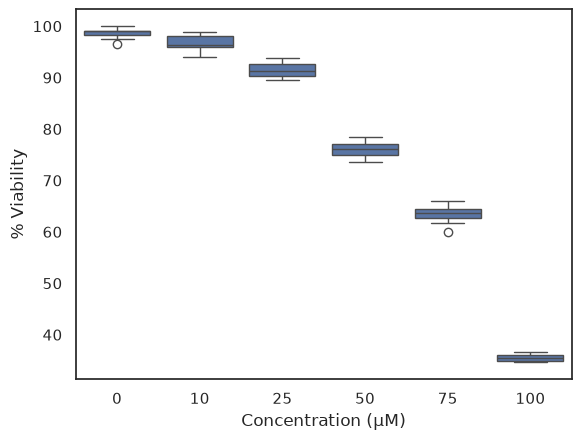

In [364]:
import matplotlib.pyplot as plt
sns.boxplot(x='Group', y='Viability', data=data_34_dia_mda)
plt.xlabel("Concentration (μM)")
plt.ylabel("% Viability")
plt.show()

In [365]:
# --- 2. Shapiro-Wilk normality test by group ---
shapiro_results = data_34_dia_mda.groupby('Group').apply(lambda g: pg.normality(g['Viability']))
print("Normality test (Shapiro-Wilk):")
print(shapiro_results[['W', 'pval']])

Normality test (Shapiro-Wilk):
                        W      pval
Group                              
0     Viability  0.921805  0.407396
10    Viability  0.968994  0.885995
100   Viability  0.886822  0.185013
25    Viability  0.952633  0.718971
50    Viability  0.989343  0.995130
75    Viability  0.971585  0.907931


In [366]:
# --- 3. Homogeneity of variances test (Levene) ---
levene_result = pg.homoscedasticity(data_34_dia_mda, dv='Viability', group='Group', method='levene')
print("\nHomogeneity of variances test (Levene):")
print(levene_result[['W', 'pval']])


Homogeneity of variances test (Levene):
               W     pval
levene  0.732088  0.60294


In [367]:
# --- 4. ANOVA selection ---
if levene_result['pval'].values[0] > 0.05:
    print("\nHomogeneous variances: We use classic ANOVA.")
    anova = pg.anova(data=data_34_dia_mda, dv='Viability', between='Group', detailed=True)
else:
    print("\nNon-homogeneous variances: We use Welch ANOVA.")
    anova = pg.welch_anova(dv='Viability', between='Group', data=data_34_dia_mda)

print("\nANOVA Result:")
print(anova)


Homogeneous variances: We use classic ANOVA.

ANOVA Result:
   Source            SS  DF           MS           F         p_unc       np2
0   Group  26704.566014   5  5340.913203  2786.08311  6.860418e-58  0.996566
1  Within     92.015860  48     1.916997         NaN           NaN       NaN


In [368]:
pg.kruskal(data_34_dia_mda, dv="Viability", between="Group")

,Source,ddof1,H,p_unc
Kruskal,Group,5,50.994737,8.670232e-10


In [369]:
# --- 5. Dunnett post-hoc test ---

control = data_34_dia_mda['Group'].unique()[0]
dunnett = sp.posthoc_dunnett(data_34_dia_mda, val_col='Viability', group_col='Group', control=control)
print(f"\nDunnett post-hoc (vs {control}):")
print(dunnett)


Dunnett post-hoc (vs 0):
            0        10   25   50   75  100
0    1.000000  0.012082  0.0  0.0  0.0  0.0
10   0.012082  1.000000  NaN  NaN  NaN  NaN
25   0.000000       NaN  1.0  NaN  NaN  NaN
50   0.000000       NaN  NaN  1.0  NaN  NaN
75   0.000000       NaN  NaN  NaN  1.0  NaN
100  0.000000       NaN  NaN  NaN  NaN  1.0


In [370]:
# --- 6. Tukey HSD post-hoc test ---
tukey_34_DIA_MDA=pg.pairwise_tukey(data_34_dia_mda, dv="Viability", between="Group", effsize='hedges')
#tukey_34_DIA.to_csv("tukey_34DIA.csv")

In [371]:
tukey_34_DIA_MDA

,A,B,mean_A,mean_B,diff,se,T,p_tukey,hedges
0,0,10,98.681733,96.622475,2.059258,0.652686,3.155050,3.116855e-02,1.468798
1,0,100,98.681733,35.574495,63.107238,0.652686,96.688473,2.664535e-15,62.366293
2,0,25,98.681733,91.445707,7.236026,0.652686,11.086530,1.187939e-13,5.446005
3,0,50,98.681733,75.978535,22.703197,0.652686,34.784243,2.664535e-15,16.395677
4,0,75,98.681733,63.352273,35.329460,0.652686,54.129315,2.664535e-15,22.418757
5,10,100,96.622475,35.574495,61.047980,0.652686,93.533423,2.664535e-15,48.538452
6,10,25,96.622475,91.445707,5.176768,0.652686,7.931479,4.139897e-09,3.396248
7,10,50,96.622475,75.978535,20.643939,0.652686,31.629193,2.664535e-15,13.121144
8,10,75,96.622475,63.352273,33.270202,0.652686,50.974265,2.664535e-15,19.077403
9,100,25,35.574495,91.445707,-55.871212,0.652686,-85.601943,2.664535e-15,-47.532078


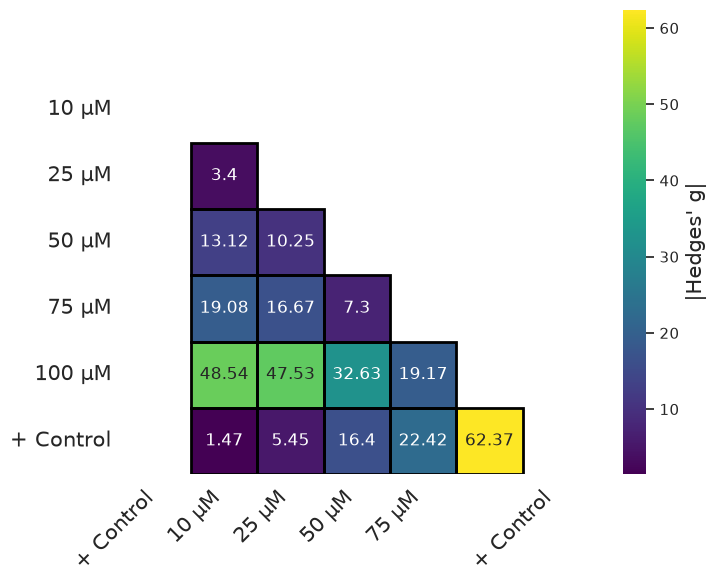

In [372]:
tukey_34_DIA_MDA["A"] = tukey_34_DIA_MDA["A"].astype(str)
tukey_34_DIA_MDA["B"] = tukey_34_DIA_MDA["B"].astype(str)

orden = ['+ Control', '10', '25', '50', '75', '100']
matriz_g = pd.DataFrame(np.nan, index=orden, columns=orden)

for _, row in tukey_34_DIA_MDA.iterrows():
    a, b = row["A"], row["B"]
    g = abs(row["hedges"])
    matriz_g.loc[a, b] = g
    matriz_g.loc[b, a] = g

def format_um(x):
    return f"{x} µM" if x in ['10', '25', '50', '75', '100'] else "+ Control"

etiquetas_filas = ['' if x == '+ Control' else format_um(x) for x in matriz_g.index]
etiquetas_columnas = ['' if x == '100' else format_um(x) for x in matriz_g.columns]

matriz_annot = matriz_g.copy().round(2).astype(str)
matriz_annot[matriz_g.isna()] = "–"

mask_lower = np.triu(np.ones_like(matriz_g, dtype=bool))


highlight_mask = (matriz_g >= 1.0) & (~mask_lower)


plt.figure(figsize=(8, 6))
sns.set(style="white")

ax = sns.heatmap(
    matriz_g,
    annot=matriz_annot,
    fmt="",
    cmap="viridis",
    mask=mask_lower,
    square=True,
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': "|Hedges' g|"},
    xticklabels=etiquetas_columnas,
    yticklabels=etiquetas_filas
)
for i in range(len(matriz_g)):
    for j in range(len(matriz_g)):
        if highlight_mask.iloc[i, j]:
            ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor='black', linewidth=2))


for i in range(len(matriz_g)):
    if not pd.isna(matriz_g.iloc[i, 0]):
        ax.add_patch(plt.Rectangle((0, i), 1, 1, fill=False, edgecolor='red', linewidth=5))

ax.figure.axes[-1].yaxis.label.set_size(15)
#plt.title("Mapa de calor del tamaño del efecto (Hedges' g)\nComparaciones significativas entre tratamientos", fontsize=14, weight='bold')
plt.xticks(rotation=45, ha='right', fontsize=15)
plt.yticks(rotation=0, fontsize=15)
plt.tight_layout()
plt.savefig("hedges_mda.png", dpi=300)
plt.show()


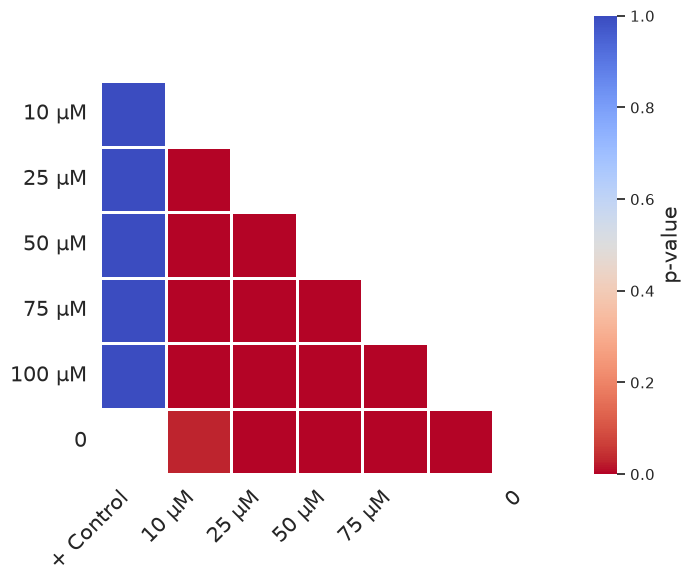

In [373]:
unique_pairs = set()
filtered_rows = []
for _, row in tukey_34_DIA_MDA.iterrows():
    pair = tuple(sorted((str(row['A']), str(row['B']))))
    if pair not in unique_pairs and row['A'] != row['B']:
        unique_pairs.add(pair)
        filtered_rows.append(row)
df_filtered = pd.DataFrame(filtered_rows)

orden_grupos = ['+ Control', '10', '25', '50', '75', '100']

matriz_p = pd.DataFrame(np.ones((len(orden_grupos), len(orden_grupos))),
                        index=orden_grupos, columns=orden_grupos)
for _, row in df_filtered.iterrows():
    a, b = str(row['A']), str(row['B'])
    p_val = row['p_tukey']
    matriz_p.loc[a, b] = p_val
    matriz_p.loc[b, a] = p_val

mask = np.triu(np.ones_like(matriz_p, dtype=bool))

def format_label(label, hide_label=None, add_unit=False):
    if label == hide_label:
        return ''
    if add_unit and label in ['10',"25", '50', '75', '100']:
        return f'{label} µM'
    return label

etiquetas_filas = [format_label(x, hide_label='+ Control', add_unit=True) for x in matriz_p.index]
etiquetas_columnas = [format_label(x, hide_label='100', add_unit=True) for x in matriz_p.columns]

plt.figure(figsize=(8, 6))
sns.set(style="white")

ax = sns.heatmap(
    matriz_p,
    mask=mask,
    annot=False,
    fmt=".2g",
    cmap="coolwarm_r",
    cbar_kws={'label': 'p-value'},
    linewidths=1,
    square=True,
    annot_kws={"size": 12, "weight": "bold"},
    yticklabels=etiquetas_filas,
    xticklabels=etiquetas_columnas,
    vmin=0,
    vmax=1

)
ax.figure.axes[-1].yaxis.label.set_size(15)
plt.xticks(rotation=45, ha='right', fontsize=15)
plt.yticks(rotation=0, fontsize=15)
plt.tight_layout()
sns.despine(left=True, bottom=True)
plt.savefig("mapa_significancia_mda.png", dpi=300)
plt.show()

##3,4-DIA with MCF7


In [374]:
data_34_dia_mc.head()

,Viability,Group,Concentration,Dataset
0,99.152542,0,0.0,"3,4-DIA"
1,100.000000,0,0.0,"3,4-DIA"
2,98.305085,0,0.0,"3,4-DIA"
3,96.610169,0,0.0,"3,4-DIA"
4,100.000000,0,0.0,"3,4-DIA"


In [375]:
#---- 0. Descriptive Statistics -------
data_34_dia_mc.groupby("Group").describe().T

Group                         0         10         100         25         50  \
Viability     count    9.000000   9.000000    9.000000   9.000000   9.000000   
              mean    98.681733  85.866493   37.486410  69.645575  60.687106   
              std      1.129944   1.738761    2.041029   2.058157   1.385307   
              min     96.610169  83.953033   35.420744  66.536204  58.512720   
              25%     98.305085  84.344423   36.203522  68.297456  59.882583   
              50%     99.152542  85.322896   36.399217  70.254403  60.861057   
              75%     99.152542  87.475538   39.530333  71.232877  61.839530   
              max    100.000000  88.454012   40.508806  72.015656  62.426614   
Concentration count    9.000000   9.000000    9.000000   9.000000   9.000000   
              mean     0.000000  10.000000  100.000000  25.000000  50.000000   
              std      0.000000   0.000000    0.000000   0.000000   0.000000   
              min      0.000000  10.000000  100.000000  25.000000  50.000000   
              25%      0.000000  10.000000  100.000000  25.000000  50.000000   
              50%      0.000000  10.000000  100.000000  25.000000  50.000000   
              75%      0.000000  10.000000  100.000000  25.000000  50.000000   
              max      0.000000  10.000000  100.000000  25.000000  50.000000   

Group                       75  
Viability     count   9.000000  
              mean   41.356817  
              std     1.366364  
              min    39.334638  
              25%    40.313112  
              50%    41.682975  
              75%    42.465753  
              max    43.248532  
Concentration count   9.000000  
              mean   75.000000  
              std     0.000000  
              min    75.000000  
              25%    75.000000  
              50%    75.000000  
              75%    75.000000  
              max    75.000000

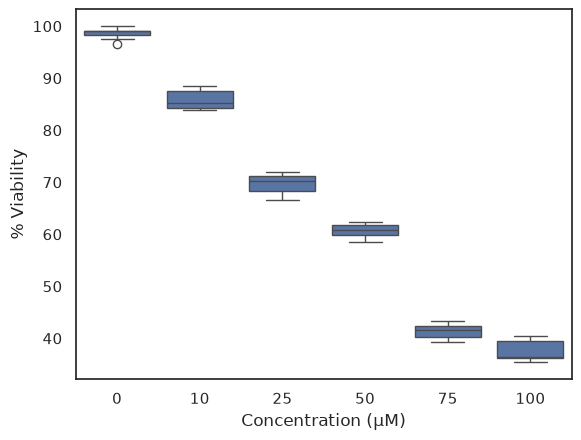

In [376]:
import matplotlib.pyplot as plt
sns.boxplot(x='Group', y='Viability', data=data_34_dia_mc)
plt.xlabel("Concentration (μM)")
plt.ylabel("% Viability")
plt.show()

In [377]:
# --- 2. Shapiro-Wilk normality test by group ---
shapiro_results = data_34_dia_mc.groupby('Group').apply(lambda g: pg.normality(g['Viability']))
print("Normality test (Shapiro-Wilk):")
print(shapiro_results[['W', 'pval']])

Normality test (Shapiro-Wilk):
                        W      pval
Group                              
0     Viability  0.921805  0.407396
10    Viability  0.891421  0.206342
100   Viability  0.821792  0.036101
25    Viability  0.918766  0.382119
50    Viability  0.927711  0.459863
75    Viability  0.928055  0.463045


In [378]:
# --- 3. Homogeneity of variances test (Levene) ---
levene_result = pg.homoscedasticity(data_34_dia_mc, dv='Viability', group='Group', method='levene')
print("\nHomogeneity of variances test (Levene):")
print(levene_result[['W', 'pval']])


Homogeneity of variances test (Levene):
               W      pval
levene  0.749817  0.590294


In [379]:
# --- 4. ANOVA selection ---
if levene_result['pval'].values[0] > 0.05:
    print("\nHomogeneous variances: We use classic ANOVA.")
    anova = pg.anova(data=data_34_dia_mc, dv='Viability', between='Group', detailed=True)
else:
    print("\nNon-homogeneous variances: We use Welch ANOVA.")
    anova = pg.welch_anova(dv='Viability', between='Group', data=data_34_dia_mc)

print("\nANOVA Result:")
print(anova)


Homogeneous variances: We use classic ANOVA.

ANOVA Result:
   Source            SS  DF           MS            F         p_unc       np2
0   Group  26313.644432   5  5262.728886  1915.124209  5.324040e-54  0.995012
1  Within    131.903187  48     2.747983          NaN           NaN       NaN


In [380]:
pg.kruskal(data_34_dia_mc, dv="Viability", between="Group")

,Source,ddof1,H,p_unc
Kruskal,Group,5,51.103734,8.235685e-10


In [381]:
# --- 5. Dunnett post-hoc test ---

control = data_34_dia_mc['Group'].unique()[0]
dunnett = sp.posthoc_dunnett(data_34_dia_mc, val_col='Viability', group_col='Group', control=control)
print(f"\nDunnett post-hoc (vs {control}):")
print(dunnett)


Dunnett post-hoc (vs 0):
       0   10   25   50   75  100
0    1.0  0.0  0.0  0.0  0.0  0.0
10   0.0  1.0  NaN  NaN  NaN  NaN
25   0.0  NaN  1.0  NaN  NaN  NaN
50   0.0  NaN  NaN  1.0  NaN  NaN
75   0.0  NaN  NaN  NaN  1.0  NaN
100  0.0  NaN  NaN  NaN  NaN  1.0


In [382]:
# --- 6. Tukey HSD post-hoc test ---
tukey_34_DIA_MC=pg.pairwise_tukey(data_34_dia_mc, dv="Viability", between="Group", effsize='hedges')
#tukey_34_DIA.to_csv("tukey_35DIA.csv")

In [383]:
tukey_34_DIA_MC

,A,B,mean_A,mean_B,diff,se,T,p_tukey,hedges
0,0,10,98.681733,85.866493,12.815240,0.781449,16.399325,2.664535e-15,8.323674
1,0,100,98.681733,37.486410,61.195322,0.781449,78.310042,2.664535e-15,35.329853
2,0,25,98.681733,69.645575,29.036157,0.781449,37.156806,2.664535e-15,16.656334
3,0,50,98.681733,60.687106,37.994627,0.781449,48.620723,2.664535e-15,28.625612
4,0,75,98.681733,41.356817,57.324916,0.781449,73.357185,2.664535e-15,43.545872
5,10,100,85.866493,37.486410,48.380083,0.781449,61.910717,2.664535e-15,24.302747
6,10,25,85.866493,69.645575,16.220918,0.781449,20.757481,2.664535e-15,8.108747
7,10,50,85.866493,60.687106,25.179387,0.781449,32.221398,2.664535e-15,15.254690
8,10,75,85.866493,41.356817,44.509676,0.781449,56.957860,2.664535e-15,27.109096
9,100,25,37.486410,69.645575,-32.159165,0.781449,-41.153236,2.664535e-15,-14.943215


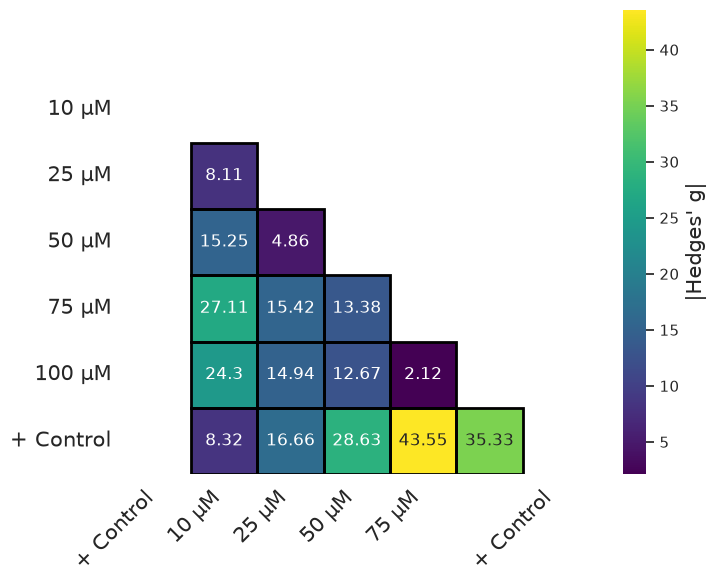

In [384]:
tukey_34_DIA_MC["A"] = tukey_34_DIA_MC["A"].astype(str)
tukey_34_DIA_MC["B"] = tukey_34_DIA_MC["B"].astype(str)

orden = ['+ Control', '10', '25', '50', '75', '100']
matriz_g = pd.DataFrame(np.nan, index=orden, columns=orden)

for _, row in tukey_34_DIA_MC.iterrows():
    a, b = row["A"], row["B"]
    g = abs(row["hedges"])
    matriz_g.loc[a, b] = g
    matriz_g.loc[b, a] = g

def format_um(x):
    return f"{x} µM" if x in ['10', '25', '50', '75', '100'] else "+ Control"

etiquetas_filas = ['' if x == '+ Control' else format_um(x) for x in matriz_g.index]
etiquetas_columnas = ['' if x == '100' else format_um(x) for x in matriz_g.columns]

matriz_annot = matriz_g.copy().round(2).astype(str)
matriz_annot[matriz_g.isna()] = "–"

mask_lower = np.triu(np.ones_like(matriz_g, dtype=bool))


highlight_mask = (matriz_g >= 1.0) & (~mask_lower)


plt.figure(figsize=(8, 6))
sns.set(style="white")

ax = sns.heatmap(
    matriz_g,
    annot=matriz_annot,
    fmt="",
    cmap="viridis",
    mask=mask_lower,
    square=True,
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': "|Hedges' g|"},
    xticklabels=etiquetas_columnas,
    yticklabels=etiquetas_filas
)
for i in range(len(matriz_g)):
    for j in range(len(matriz_g)):
        if highlight_mask.iloc[i, j]:
            ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor='black', linewidth=2))


for i in range(len(matriz_g)):
    if not pd.isna(matriz_g.iloc[i, 0]):
        ax.add_patch(plt.Rectangle((0, i), 1, 1, fill=False, edgecolor='red', linewidth=5))

ax.figure.axes[-1].yaxis.label.set_size(15)
#plt.title("Mapa de calor del tamaño del efecto (Hedges' g)\nComparaciones significativas entre tratamientos", fontsize=14, weight='bold')
plt.xticks(rotation=45, ha='right', fontsize=15)
plt.yticks(rotation=0, fontsize=15)
plt.tight_layout()
plt.savefig("hedges_mc.png", dpi=300)
plt.show()



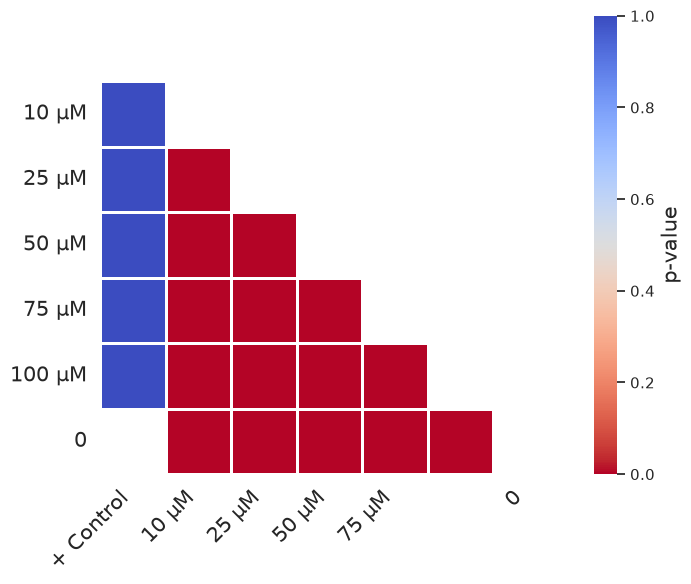

In [385]:
unique_pairs = set()
filtered_rows = []
for _, row in tukey_34_DIA_MC.iterrows():
    pair = tuple(sorted((str(row['A']), str(row['B']))))
    if pair not in unique_pairs and row['A'] != row['B']:
        unique_pairs.add(pair)
        filtered_rows.append(row)
df_filtered = pd.DataFrame(filtered_rows)

orden_grupos = ['+ Control', '10', '25', '50', '75', '100']

matriz_p = pd.DataFrame(np.ones((len(orden_grupos), len(orden_grupos))),
                        index=orden_grupos, columns=orden_grupos)
for _, row in df_filtered.iterrows():
    a, b = str(row['A']), str(row['B'])
    p_val = row['p_tukey']
    matriz_p.loc[a, b] = p_val
    matriz_p.loc[b, a] = p_val

mask = np.triu(np.ones_like(matriz_p, dtype=bool))

def format_label(label, hide_label=None, add_unit=False):
    if label == hide_label:
        return ''
    if add_unit and label in ['10',"25", '50', '75', '100']:
        return f'{label} µM'
    return label

etiquetas_filas = [format_label(x, hide_label='+ Control', add_unit=True) for x in matriz_p.index]
etiquetas_columnas = [format_label(x, hide_label='100', add_unit=True) for x in matriz_p.columns]

plt.figure(figsize=(8, 6))
sns.set(style="white")

ax = sns.heatmap(
    matriz_p,
    mask=mask,
    annot=False,
    fmt=".2g",
    cmap="coolwarm_r",
    cbar_kws={'label': 'p-value'},
    linewidths=1,
    square=True,
    annot_kws={"size": 12, "weight": "bold"},
    yticklabels=etiquetas_filas,
    xticklabels=etiquetas_columnas,
    vmin=0,
    vmax=1

)
ax.figure.axes[-1].yaxis.label.set_size(15)
plt.xticks(rotation=45, ha='right', fontsize=15)
plt.yticks(rotation=0, fontsize=15)
plt.tight_layout()
sns.despine(left=True, bottom=True)
plt.savefig("mapa_significancia_mc.png", dpi=300)
plt.show()

##3,5-DIA with MDA-MB-231

In [386]:
data_35_dia_mda.head()

,Viability,Group,Concentration,Dataset
0,99.152542,0,0.0,"3,5-DIA"
1,100.000000,0,0.0,"3,5-DIA"
2,98.305085,0,0.0,"3,5-DIA"
3,96.610169,0,0.0,"3,5-DIA"
4,100.000000,0,0.0,"3,5-DIA"


In [387]:
#---- 0. Descriptive Statistics -------
data_35_dia_mda.groupby("Group").describe().T

Group                         0         10         100         25         50  \
Viability     count    9.000000   9.000000    9.000000   9.000000   9.000000   
              mean    98.681733  98.611111   36.742424  95.643939  79.987374   
              std      1.129944   1.008867    1.462447   1.476180   1.355854   
              min     96.610169  96.875000   34.375000  94.034091  77.272727   
              25%     98.305085  98.295455   36.079545  94.318182  79.545455   
              50%     99.152542  98.863636   36.363636  95.170455  80.113636   
              75%     99.152542  99.431818   38.068182  97.159091  80.681818   
              max    100.000000  99.715909   38.636364  97.727273  82.102273   
Concentration count    9.000000   9.000000    9.000000   9.000000   9.000000   
              mean     0.000000  10.000000  100.000000  25.000000  50.000000   
              std      0.000000   0.000000    0.000000   0.000000   0.000000   
              min      0.000000  10.000000  100.000000  25.000000  50.000000   
              25%      0.000000  10.000000  100.000000  25.000000  50.000000   
              50%      0.000000  10.000000  100.000000  25.000000  50.000000   
              75%      0.000000  10.000000  100.000000  25.000000  50.000000   
              max      0.000000  10.000000  100.000000  25.000000  50.000000   

Group                       75  
Viability     count   9.000000  
              mean   63.825758  
              std     0.887074  
              min    62.784091  
              25%    63.068182  
              50%    63.636364  
              75%    64.488636  
              max    65.056818  
Concentration count   9.000000  
              mean   75.000000  
              std     0.000000  
              min    75.000000  
              25%    75.000000  
              50%    75.000000  
              75%    75.000000  
              max    75.000000

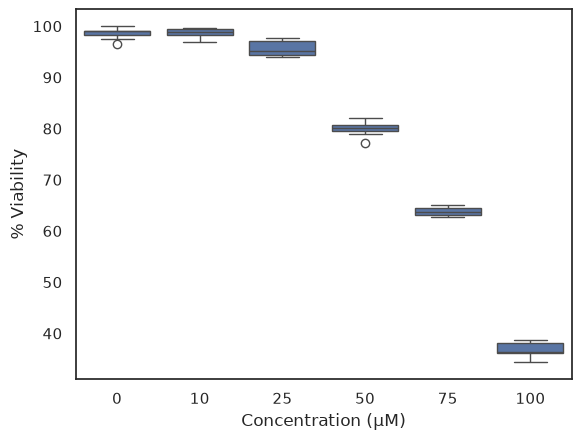

In [388]:
import matplotlib.pyplot as plt
sns.boxplot(x='Group', y='Viability', data=data_35_dia_mda)
plt.xlabel("Concentration (μM)")
plt.ylabel("% Viability")
plt.show()

In [389]:
# --- 2. Shapiro-Wilk normality test by group ---
shapiro_results = data_35_dia_mda.groupby('Group').apply(lambda g: pg.normality(g['Viability']))
print("Normality test (Shapiro-Wilk):")
print(shapiro_results[['W', 'pval']])

Normality test (Shapiro-Wilk):
                        W      pval
Group                              
0     Viability  0.921805  0.407396
10    Viability  0.887742  0.189115
100   Viability  0.928576  0.467901
25    Viability  0.866009  0.111388
50    Viability  0.964930  0.848233
75    Viability  0.893998  0.219224


In [390]:
# --- 3. Homogeneity of variances test (Levene) ---
levene_result = pg.homoscedasticity(data_35_dia_mda, dv='Viability', group='Group', method='levene')
print("\nHomogeneity of variances test (Levene):")
print(levene_result[['W', 'pval']])


Homogeneity of variances test (Levene):
               W      pval
levene  0.676846  0.643041


In [391]:
# --- 4. ANOVA selection ---
if levene_result['pval'].values[0] > 0.05:
    print("\nHomogeneous variances: We use classic ANOVA.")
    anova = pg.anova(data=data_35_dia_mda, dv='Viability', between='Group', detailed=True)
else:
    print("\nNon-homogeneous variances: We use Welch ANOVA.")
    anova = pg.welch_anova(dv='Viability', between='Group', data=data_35_dia_mda)

print("\nANOVA Result:")
print(anova)


Homogeneous variances: We use classic ANOVA.

ANOVA Result:
   Source            SS  DF           MS            F         p_unc       np2
0   Group  27592.913608   5  5518.582722  3584.393439  1.654569e-60  0.997329
1  Within     73.901477  48     1.539614          NaN           NaN       NaN


In [392]:
pg.kruskal(data_35_dia_mda, dv="Viability", between="Group")

,Source,ddof1,H,p_unc
Kruskal,Group,5,49.135831,2.081818e-09


In [393]:
# --- 5. Dunnett post-hoc test ---

control = data_35_dia_mda['Group'].unique()[0]
dunnett = sp.posthoc_dunnett(data_35_dia_mda, val_col='Viability', group_col='Group', control=control)
print(f"\nDunnett post-hoc (vs {control}):")
print(dunnett)


Dunnett post-hoc (vs 0):
            0       10        25   50   75  100
0    1.000000  0.99998  0.000029  0.0  0.0  0.0
10   0.999980  1.00000       NaN  NaN  NaN  NaN
25   0.000029      NaN  1.000000  NaN  NaN  NaN
50   0.000000      NaN       NaN  1.0  NaN  NaN
75   0.000000      NaN       NaN  NaN  1.0  NaN
100  0.000000      NaN       NaN  NaN  NaN  1.0


In [394]:
# --- 6. Tukey HSD post-hoc test ---
tukey_35_DIA_MDA=pg.pairwise_tukey(data_35_dia_mda, dv="Viability", between="Group", effsize='hedges')
#tukey_35_DIA.to_csv("tukey_35DIA.csv")

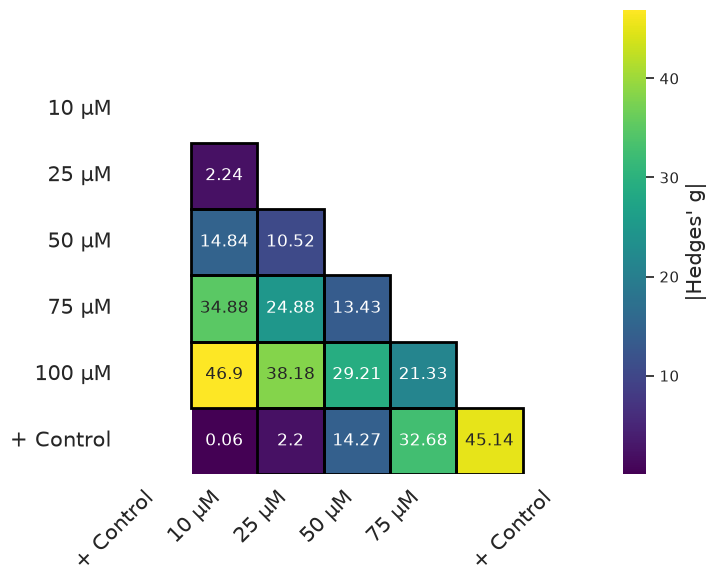

In [395]:
tukey_35_DIA_MDA["A"] = tukey_35_DIA_MDA["A"].astype(str)
tukey_35_DIA_MDA["B"] = tukey_35_DIA_MDA["B"].astype(str)

orden = ['+ Control', '10', '25', '50', '75', '100']
matriz_g = pd.DataFrame(np.nan, index=orden, columns=orden)

for _, row in tukey_35_DIA_MDA.iterrows():
    a, b = row["A"], row["B"]
    g = abs(row["hedges"])
    matriz_g.loc[a, b] = g
    matriz_g.loc[b, a] = g

def format_um(x):
    return f"{x} µM" if x in ['10', '25', '50', '75', '100'] else "+ Control"

etiquetas_filas = ['' if x == '+ Control' else format_um(x) for x in matriz_g.index]
etiquetas_columnas = ['' if x == '100' else format_um(x) for x in matriz_g.columns]

matriz_annot = matriz_g.copy().round(2).astype(str)
matriz_annot[matriz_g.isna()] = "–"

mask_lower = np.triu(np.ones_like(matriz_g, dtype=bool))


highlight_mask = (matriz_g >= 1.0) & (~mask_lower)


plt.figure(figsize=(8, 6))
sns.set(style="white")

ax = sns.heatmap(
    matriz_g,
    annot=matriz_annot,
    fmt="",
    cmap="viridis",
    mask=mask_lower,
    square=True,
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': "|Hedges' g|"},
    xticklabels=etiquetas_columnas,
    yticklabels=etiquetas_filas
)
for i in range(len(matriz_g)):
    for j in range(len(matriz_g)):
        if highlight_mask.iloc[i, j]:
            ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor='black', linewidth=2))


for i in range(len(matriz_g)):
    if not pd.isna(matriz_g.iloc[i, 0]):
        ax.add_patch(plt.Rectangle((0, i), 1, 1, fill=False, edgecolor='red', linewidth=5))

ax.figure.axes[-1].yaxis.label.set_size(15)
#plt.title("Mapa de calor del tamaño del efecto (Hedges' g)\nComparaciones significativas entre tratamientos", fontsize=14, weight='bold')
plt.xticks(rotation=45, ha='right', fontsize=15)
plt.yticks(rotation=0, fontsize=15)
plt.tight_layout()
plt.savefig("hedges_mda.png", dpi=300)
plt.show()


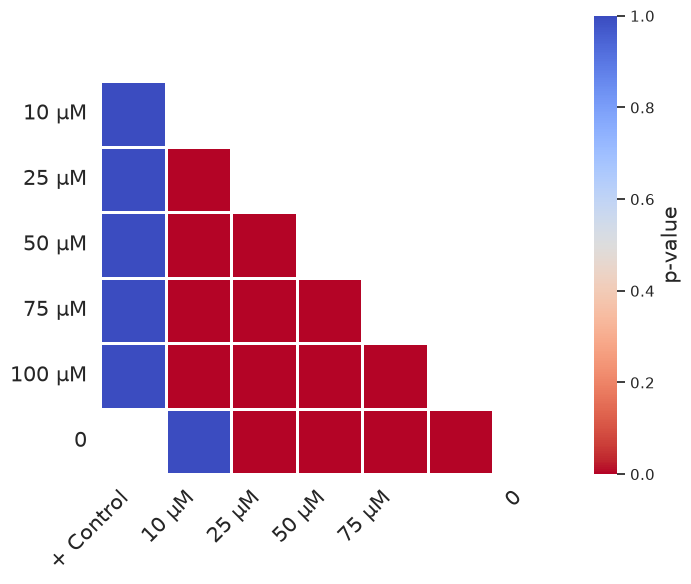

In [396]:
unique_pairs = set()
filtered_rows = []
for _, row in tukey_35_DIA_MDA.iterrows():
    pair = tuple(sorted((str(row['A']), str(row['B']))))
    if pair not in unique_pairs and row['A'] != row['B']:
        unique_pairs.add(pair)
        filtered_rows.append(row)
df_filtered = pd.DataFrame(filtered_rows)

orden_grupos = ['+ Control', '10', '25', '50', '75', '100']

matriz_p = pd.DataFrame(np.ones((len(orden_grupos), len(orden_grupos))),
                        index=orden_grupos, columns=orden_grupos)
for _, row in df_filtered.iterrows():
    a, b = str(row['A']), str(row['B'])
    p_val = row['p_tukey']
    matriz_p.loc[a, b] = p_val
    matriz_p.loc[b, a] = p_val

mask = np.triu(np.ones_like(matriz_p, dtype=bool))

def format_label(label, hide_label=None, add_unit=False):
    if label == hide_label:
        return ''
    if add_unit and label in ['10',"25", '50', '75', '100']:
        return f'{label} µM'
    return label

etiquetas_filas = [format_label(x, hide_label='+ Control', add_unit=True) for x in matriz_p.index]
etiquetas_columnas = [format_label(x, hide_label='100', add_unit=True) for x in matriz_p.columns]

plt.figure(figsize=(8, 6))
sns.set(style="white")

ax = sns.heatmap(
    matriz_p,
    mask=mask,
    annot=False,
    fmt=".2g",
    cmap="coolwarm_r",
    cbar_kws={'label': 'p-value'},
    linewidths=1,
    square=True,
    annot_kws={"size": 12, "weight": "bold"},
    yticklabels=etiquetas_filas,
    xticklabels=etiquetas_columnas,
    vmin=0,
    vmax=1

)
ax.figure.axes[-1].yaxis.label.set_size(15)
plt.xticks(rotation=45, ha='right', fontsize=15)
plt.yticks(rotation=0, fontsize=15)
plt.tight_layout()
sns.despine(left=True, bottom=True)
plt.savefig("mapa_significancia_mc.png", dpi=300)
plt.show()

##3,5-DIA with MCF7

In [397]:
data_35_dia_mc.head()

,Viability,Group,Concentration,Dataset
0,99.152542,0,0.0,"3,5-DIA"
1,100.000000,0,0.0,"3,5-DIA"
2,98.305085,0,0.0,"3,5-DIA"
3,96.610169,0,0.0,"3,5-DIA"
4,100.000000,0,0.0,"3,5-DIA"


In [398]:
#---- 0. Descriptive Statistics -------
data_35_dia_mc.groupby("Group").describe().T

Group                         0         10         100         25         50  \
Viability     count    9.000000   9.000000    9.000000   9.000000   9.000000   
              mean    98.681733  91.215482   36.486193  72.385301  64.753207   
              std      1.129944   0.883039    1.366753   1.004757   1.353850   
              min     96.610169  90.410959   34.833659  71.232877  62.622309   
              25%     98.305085  90.606654   35.420744  71.624266  63.600783   
              50%     99.152542  90.606654   36.203522  72.211350  64.774951   
              75%     99.152542  91.585127   37.573386  72.798434  65.753425   
              max    100.000000  92.954990   38.551859  73.972603  66.340509   
Concentration count    9.000000   9.000000    9.000000   9.000000   9.000000   
              mean     0.000000  10.000000  100.000000  25.000000  50.000000   
              std      0.000000   0.000000    0.000000   0.000000   0.000000   
              min      0.000000  10.000000  100.000000  25.000000  50.000000   
              25%      0.000000  10.000000  100.000000  25.000000  50.000000   
              50%      0.000000  10.000000  100.000000  25.000000  50.000000   
              75%      0.000000  10.000000  100.000000  25.000000  50.000000   
              max      0.000000  10.000000  100.000000  25.000000  50.000000   

Group                       75  
Viability     count   9.000000  
              mean   42.009132  
              std     1.157746  
              min    40.313112  
              25%    41.291585  
              50%    41.878669  
              75%    42.857143  
              max    43.835616  
Concentration count   9.000000  
              mean   75.000000  
              std     0.000000  
              min    75.000000  
              25%    75.000000  
              50%    75.000000  
              75%    75.000000  
              max    75.000000

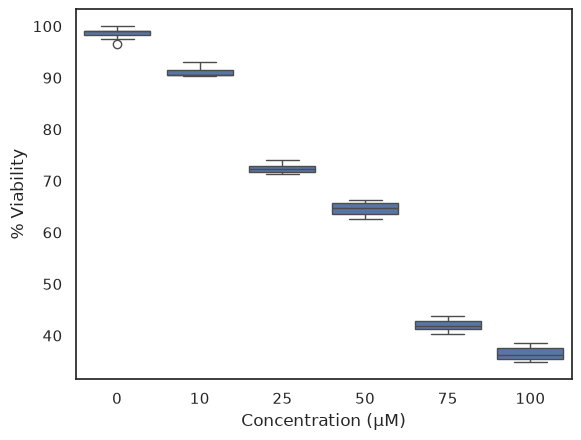

In [399]:
import matplotlib.pyplot as plt
sns.boxplot(x='Group', y='Viability', data=data_35_dia_mc)
plt.xlabel("Concentration (μM)")
plt.ylabel("% Viability")
plt.show()

In [400]:
# --- 2. Shapiro-Wilk normality test by group ---
shapiro_results = data_35_dia_mc.groupby('Group').apply(lambda g: pg.normality(g['Viability']))
print("Normality test (Shapiro-Wilk):")
print(shapiro_results[['W', 'pval']])

Normality test (Shapiro-Wilk):
                        W      pval
Group                              
0     Viability  0.921805  0.407396
10    Viability  0.828674  0.043151
100   Viability  0.909431  0.311911
25    Viability  0.920302  0.394743
50    Viability  0.926849  0.451930
75    Viability  0.962231  0.821359


In [401]:
# --- 3. Homogeneity of variances test (Levene) ---
levene_result = pg.homoscedasticity(data_35_dia_mc, dv='Viability', group='Group', method='levene')
print("\nHomogeneity of variances test (Levene):")
print(levene_result[['W', 'pval']])


Homogeneity of variances test (Levene):
             W      pval
levene  0.4364  0.820907


In [402]:
# --- 4. ANOVA selection ---
if levene_result['pval'].values[0] > 0.05:
    print("\nHomogeneous variances: We use classic ANOVA.")
    anova = pg.anova(data=data_35_dia_mc, dv='Viability', between='Group', detailed=True)
else:
    print("\nNon-homogeneous variances: We use Welch ANOVA.")
    anova = pg.welch_anova(dv='Viability', between='Group', data=data_35_dia_mc)

print("\nANOVA Result:")
print(anova)


Homogeneous variances: We use classic ANOVA.

ANOVA Result:
   Source            SS  DF           MS            F         p_unc       np2
0   Group  28599.562148   5  5719.912430  4233.123325  3.085479e-62  0.997737
1  Within     64.858918  48     1.351227          NaN           NaN       NaN


In [403]:
pg.kruskal(data_35_dia_mc, dv="Viability", between="Group")

,Source,ddof1,H,p_unc
Kruskal,Group,5,51.58478,6.563153e-10


In [404]:
# --- 5. Dunnett post-hoc test ---

control = data_35_dia_mc['Group'].unique()[0]
dunnett = sp.posthoc_dunnett(data_35_dia_mc, val_col='Viability', group_col='Group', control=control)
print(f"\nDunnett post-hoc (vs {control}):")
print(dunnett)


Dunnett post-hoc (vs 0):
       0   10   25   50   75  100
0    1.0  0.0  0.0  0.0  0.0  0.0
10   0.0  1.0  NaN  NaN  NaN  NaN
25   0.0  NaN  1.0  NaN  NaN  NaN
50   0.0  NaN  NaN  1.0  NaN  NaN
75   0.0  NaN  NaN  NaN  1.0  NaN
100  0.0  NaN  NaN  NaN  NaN  1.0


In [405]:
# --- 6. Tukey HSD post-hoc test ---
tukey_35_DIA_MC=pg.pairwise_tukey(data_35_dia_mc, dv="Viability", between="Group", effsize='hedges')
#tukey_35_DIA.to_csv("tukey_35DIA.csv")

In [406]:
tukey_35_DIA_MC

,A,B,mean_A,mean_B,diff,se,T,p_tukey,hedges
0,0,10,98.681733,91.215482,7.466251,0.547972,13.625254,2.664535e-15,7.012304
1,0,100,98.681733,36.486193,62.195540,0.547972,113.501413,2.664535e-15,47.237765
2,0,25,98.681733,72.385301,26.296431,0.547972,47.988684,2.664535e-15,23.423678
3,0,50,98.681733,64.753207,33.928525,0.547972,61.916587,2.664535e-15,25.913896
4,0,75,98.681733,42.009132,56.672600,0.547972,103.422532,2.664535e-15,47.182915
5,10,100,91.215482,36.486193,54.729289,0.547972,99.876159,2.664535e-15,45.300731
6,10,25,91.215482,72.385301,18.830180,0.547972,34.363430,2.664535e-15,18.960044
7,10,50,91.215482,64.753207,26.462274,0.547972,48.291333,2.664535e-15,22.050114
8,10,75,91.215482,42.009132,49.206349,0.547972,89.797278,2.664535e-15,45.516132
9,100,25,36.486193,72.385301,-35.899108,0.547972,-65.512729,2.664535e-15,-28.503479


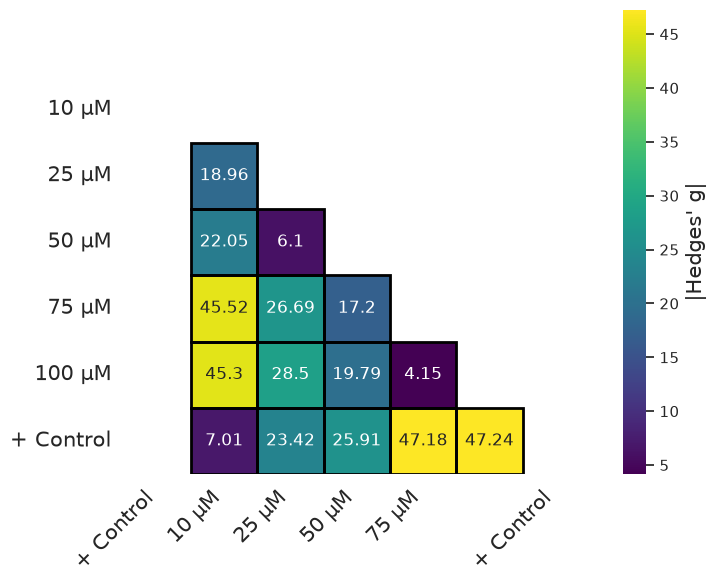

In [407]:
tukey_35_DIA_MC["A"] = tukey_35_DIA_MC["A"].astype(str)
tukey_35_DIA_MC["B"] = tukey_35_DIA_MC["B"].astype(str)

orden = ['+ Control', '10', '25', '50', '75', '100']
matriz_g = pd.DataFrame(np.nan, index=orden, columns=orden)

for _, row in tukey_35_DIA_MC.iterrows():
    a, b = row["A"], row["B"]
    g = abs(row["hedges"])
    matriz_g.loc[a, b] = g
    matriz_g.loc[b, a] = g

def format_um(x):
    return f"{x} µM" if x in ['10', '25', '50', '75', '100'] else "+ Control"

etiquetas_filas = ['' if x == '+ Control' else format_um(x) for x in matriz_g.index]
etiquetas_columnas = ['' if x == '100' else format_um(x) for x in matriz_g.columns]

matriz_annot = matriz_g.copy().round(2).astype(str)
matriz_annot[matriz_g.isna()] = "–"

mask_lower = np.triu(np.ones_like(matriz_g, dtype=bool))


highlight_mask = (matriz_g >= 1.0) & (~mask_lower)


plt.figure(figsize=(8, 6))
sns.set(style="white")

ax = sns.heatmap(
    matriz_g,
    annot=matriz_annot,
    fmt="",
    cmap="viridis",
    mask=mask_lower,
    square=True,
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': "|Hedges' g|"},
    xticklabels=etiquetas_columnas,
    yticklabels=etiquetas_filas
)
for i in range(len(matriz_g)):
    for j in range(len(matriz_g)):
        if highlight_mask.iloc[i, j]:
            ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor='black', linewidth=2))


for i in range(len(matriz_g)):
    if not pd.isna(matriz_g.iloc[i, 0]):
        ax.add_patch(plt.Rectangle((0, i), 1, 1, fill=False, edgecolor='red', linewidth=5))

ax.figure.axes[-1].yaxis.label.set_size(15)
#plt.title("Mapa de calor del tamaño del efecto (Hedges' g)\nComparaciones significativas entre tratamientos", fontsize=14, weight='bold')
plt.xticks(rotation=45, ha='right', fontsize=15)
plt.yticks(rotation=0, fontsize=15)
plt.tight_layout()
plt.savefig("hedges_mc.png", dpi=300)
plt.show()



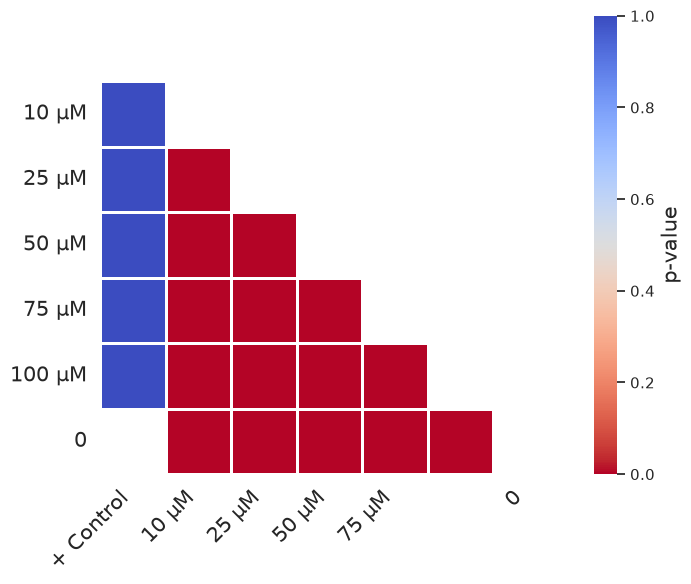

In [408]:
unique_pairs = set()
filtered_rows = []
for _, row in tukey_35_DIA_MC.iterrows():
    pair = tuple(sorted((str(row['A']), str(row['B']))))
    if pair not in unique_pairs and row['A'] != row['B']:
        unique_pairs.add(pair)
        filtered_rows.append(row)
df_filtered = pd.DataFrame(filtered_rows)

orden_grupos = ['+ Control', '10', '25', '50', '75', '100']

matriz_p = pd.DataFrame(np.ones((len(orden_grupos), len(orden_grupos))),
                        index=orden_grupos, columns=orden_grupos)
for _, row in df_filtered.iterrows():
    a, b = str(row['A']), str(row['B'])
    p_val = row['p_tukey']
    matriz_p.loc[a, b] = p_val
    matriz_p.loc[b, a] = p_val

mask = np.triu(np.ones_like(matriz_p, dtype=bool))

def format_label(label, hide_label=None, add_unit=False):
    if label == hide_label:
        return ''
    if add_unit and label in ['10',"25", '50', '75', '100']:
        return f'{label} µM'
    return label

etiquetas_filas = [format_label(x, hide_label='+ Control', add_unit=True) for x in matriz_p.index]
etiquetas_columnas = [format_label(x, hide_label='100', add_unit=True) for x in matriz_p.columns]

plt.figure(figsize=(8, 6))
sns.set(style="white")

ax = sns.heatmap(
    matriz_p,
    mask=mask,
    annot=False,
    fmt=".2g",
    cmap="coolwarm_r",
    cbar_kws={'label': 'p-value'},
    linewidths=1,
    square=True,
    annot_kws={"size": 12, "weight": "bold"},
    yticklabels=etiquetas_filas,
    xticklabels=etiquetas_columnas,
    vmin=0,
    vmax=1

)
ax.figure.axes[-1].yaxis.label.set_size(15)
plt.xticks(rotation=45, ha='right', fontsize=15)
plt.yticks(rotation=0, fontsize=15)
plt.tight_layout()
sns.despine(left=True, bottom=True)
plt.savefig("mapa_significancia_mc.png", dpi=300)
plt.show()